# **Step 1 — Set Up the Data Lake and Build the Bronze Layer**

### **-> Install required libraries**

In [1]:
# Install the libraries required for the assignment

!pip install -q pandas numpy pyarrow

### **-> Import libraries**

In [2]:
# Import libraries for data processing, file handling and timestamps

import os
import csv
import zipfile
import pandas as pd
import numpy as np

from datetime import datetime, timezone

# Configure Pandas to display all columns
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


### **-> Create the Data Lake folders**

In [3]:
# Define the main project directory

BASE_PATH = "/content/book_recommendation"

# Define paths for Bronze, Silver and Gold layers

BRONZE_PATH = os.path.join(BASE_PATH, "bronze")
SILVER_PATH = os.path.join(BASE_PATH, "silver")
GOLD_PATH = os.path.join(BASE_PATH, "gold")

# Create all three directories
# exist_ok=True prevents errors if directories already exist

os.makedirs(BRONZE_PATH, exist_ok=True)
os.makedirs(SILVER_PATH, exist_ok=True)
os.makedirs(GOLD_PATH, exist_ok=True)

# Display the created directory structure

print("Data Lake directories created successfully!")

print("\nProject Directory:", BASE_PATH)
print("Bronze Directory:", BRONZE_PATH)
print("Silver Directory:", SILVER_PATH)
print("Gold Directory:", GOLD_PATH)

print("\nFolders:", os.listdir(BASE_PATH))

Data Lake directories created successfully!

Project Directory: /content/book_recommendation
Bronze Directory: /content/book_recommendation/bronze
Silver Directory: /content/book_recommendation/silver
Gold Directory: /content/book_recommendation/gold

Folders: ['gold', 'bronze', 'silver']


### **-> Extract the uploaded Book-Crossing dataset**

In [4]:
# Define the path of the ZIP file uploaded to Google Colab

ZIP_PATH = "/content/book-crossings.zip"

# Define the directory where the original CSV files will be extracted

RAW_PATH = "/content/book_crossings_raw"

# Verify that the ZIP file exists

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        "book-crossings.zip not found! Please upload it to /content/"
    )

# Create the raw data directory

os.makedirs(RAW_PATH, exist_ok=True)

# Extract the ZIP archive

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(RAW_PATH)

# Display the extracted files

print("Dataset extracted successfully!")

print("\nExtracted files:")

for file in os.listdir(RAW_PATH):
    print(file)

Dataset extracted successfully!

Extracted files:
BX-Book-Ratings.csv
BX-Books.csv
BX-Users.csv


### **-> Load the three original CSV files**

In [5]:
# Import CSV module for handling special CSV formatting
import csv
import pandas as pd
import os


# --------------------------------------------------
# 1. Load Users Dataset
# --------------------------------------------------

# The Users file contains three columns:
# User-ID, Location, Age
#
# If an extra semicolon occurs in Location,
# combine the middle fields back into Location.

def repair_users_row(row):

    if len(row) == 3:
        return row

    if len(row) > 3:
        return [
            row[0],
            ";".join(row[1:-1]),
            row[-1]
        ]

    # Reject rows with insufficient fields
    return None


users = pd.read_csv(
    os.path.join(RAW_PATH, "BX-Users.csv"),
    sep=";",
    encoding="latin-1",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines=repair_users_row,
    dtype=str,
    keep_default_na=False
)


# --------------------------------------------------
# 2. Load Books Dataset
# --------------------------------------------------

# The Books file contains eight columns.
# QUOTE_NONE prevents malformed quotation marks
# from breaking CSV parsing.
#
# If a title contains an extra semicolon,
# combine the additional title fields.

def repair_books_row(row):

    if len(row) == 8:
        return row

    if len(row) > 8:

        extra_fields = len(row) - 8

        # Combine extra fields into the Book-Title column
        row[1:2 + extra_fields] = [
            ";".join(row[1:2 + extra_fields])
        ]

        if len(row) == 8:
            return row

    return None


books = pd.read_csv(
    os.path.join(RAW_PATH, "BX-Books.csv"),
    sep=";",
    encoding="latin-1",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines=repair_books_row,
    dtype=str,
    keep_default_na=False
)


# --------------------------------------------------
# 3. Load Book-Ratings Dataset
# --------------------------------------------------

# The Ratings file contains three columns:
# User-ID, ISBN, Book-Rating

ratings = pd.read_csv(
    os.path.join(RAW_PATH, "BX-Book-Ratings.csv"),
    sep=";",
    encoding="latin-1",
    engine="python",
    quoting=csv.QUOTE_NONE,
    dtype=str,
    keep_default_na=False
)


# --------------------------------------------------
# 4. Clean CSV field boundaries
# --------------------------------------------------

# Remove quotation marks surrounding field values.
# This does not perform data cleaning such as
# removing duplicates or missing values.

for df in [users, books, ratings]:

    df.columns = [
        col.strip().strip('"')
        for col in df.columns
    ]

    for column in df.columns:

        df[column] = (
            df[column]
            .str.strip()
            .str.strip('"')
        )


# Preserve ISBN as a string identifier

books["ISBN"] = books["ISBN"].astype("string")
ratings["ISBN"] = ratings["ISBN"].astype("string")


# --------------------------------------------------
# 5. Display Dataset Information
# --------------------------------------------------

print("ALL DATASETS LOADED SUCCESSFULLY!")

print("\nUsers Dataset Shape:", users.shape)
print("Books Dataset Shape:", books.shape)
print("Ratings Dataset Shape:", ratings.shape)

print("\nUsers Columns:", users.columns.tolist())
print("Books Columns:", books.columns.tolist())
print("Ratings Columns:", ratings.columns.tolist())

ALL DATASETS LOADED SUCCESSFULLY!

Users Dataset Shape: (278859, 3)
Books Dataset Shape: (271379, 8)
Ratings Dataset Shape: (1149780, 3)

Users Columns: ['User-ID', 'Location', 'Age']
Books Columns: ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']
Ratings Columns: ['User-ID', 'ISBN', 'Book-Rating']


### **-> Verify the loaded datasets**

In [6]:
# Display the first five records of each dataset

print("USERS DATASET")
display(users.head())

print("\nBOOKS DATASET")
display(books.head())

print("\nRATINGS DATASET")
display(ratings.head())


# Verify expected column counts

assert len(users.columns) == 3, "Users should have 3 columns"
assert len(books.columns) == 8, "Books should have 8 columns"
assert len(ratings.columns) == 3, "Ratings should have 3 columns"

# Verify required column names

assert "User-ID" in users.columns
assert "Location" in users.columns
assert "Age" in users.columns

assert "ISBN" in books.columns
assert "Book-Title" in books.columns
assert "Book-Author" in books.columns

assert "User-ID" in ratings.columns
assert "ISBN" in ratings.columns
assert "Book-Rating" in ratings.columns

print("\nDataset verification successful!")

USERS DATASET


,User-ID,Location,Age
0,1,"nyc, new york, usa",NULL
1,2,"stockton, california, usa",18
2,3,"moscow, yukon territory, russia",NULL
3,4,"porto, v.n.gaia, portugal",17
4,5,"farnborough, hants, united kingdom",NULL



BOOKS DATASET


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,"The Mummies of Urumchi"";""E. J. W. Barber",1999,W. W. Norton &amp,Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...



RATINGS DATASET


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6



Dataset verification successful!


### **-> Verify raw CSV structure**

In [7]:
# Verify the structure of each original CSV file
# Expected column counts are taken from the CSV headers.

def check_csv_structure(file_path):

    with open(
        file_path,
        "r",
        encoding="latin-1",
        newline=""
    ) as file:

        reader = csv.reader(
            file,
            delimiter=";",
            quoting=csv.QUOTE_NONE
        )

        header = next(reader)

        expected_columns = len(header)

        invalid_rows = []

        for line_number, row in enumerate(reader, start=2):

            if len(row) != expected_columns:

                invalid_rows.append({
                    "line": line_number,
                    "expected": expected_columns,
                    "found": len(row)
                })

    print("\nFile:", os.path.basename(file_path))
    print("Expected columns:", expected_columns)
    print("Malformed rows:", len(invalid_rows))

    if invalid_rows:
        print("First five problematic rows:")
        display(pd.DataFrame(invalid_rows[:5]))

    return len(invalid_rows)


# Check all three original files

users_errors = check_csv_structure(
    os.path.join(RAW_PATH, "BX-Users.csv")
)

books_errors = check_csv_structure(
    os.path.join(RAW_PATH, "BX-Books.csv")
)

ratings_errors = check_csv_structure(
    os.path.join(RAW_PATH, "BX-Book-Ratings.csv")
)


File: BX-Users.csv
Expected columns: 3
Malformed rows: 161
First five problematic rows:


,line,expected,found
0,5263,3,4
1,8197,3,4
2,9312,3,5
3,10663,3,5
4,12347,3,4



File: BX-Books.csv
Expected columns: 8
Malformed rows: 21367
First five problematic rows:


,line,expected,found
0,6,8,9
1,23,8,9
2,25,8,10
3,39,8,9
4,85,8,9



File: BX-Book-Ratings.csv
Expected columns: 3
Malformed rows: 0


### **-> Add ingestion timestamp**

In [8]:
# Generate a UTC timestamp for this data ingestion process

ingestion_timestamp = datetime.now(timezone.utc)

# Add the ingestion_timestamp column to all three datasets
# No data cleaning or filtering is performed in this step

users["ingestion_timestamp"] = ingestion_timestamp

books["ingestion_timestamp"] = ingestion_timestamp

ratings["ingestion_timestamp"] = ingestion_timestamp

# Verify that the timestamp was added successfully

print("Ingestion timestamp added successfully!")

print("\nUsers:")
display(users[["User-ID", "ingestion_timestamp"]].head())

print("\nBooks:")
display(books[["ISBN", "ingestion_timestamp"]].head())

print("\nRatings:")
display(ratings[["User-ID", "ISBN", "ingestion_timestamp"]].head())

Ingestion timestamp added successfully!

Users:


,User-ID,ingestion_timestamp
0,1,2026-11-24 17:11:57.821263+00:00
1,2,2026-11-24 17:11:57.821263+00:00
2,3,2026-11-24 17:11:57.821263+00:00
3,4,2026-11-24 17:11:57.821263+00:00
4,5,2026-11-24 17:11:57.821263+00:00



Books:


,ISBN,ingestion_timestamp
0,0195153448,2026-11-24 17:11:57.821263+00:00
1,0002005018,2026-11-24 17:11:57.821263+00:00
2,0060973129,2026-11-24 17:11:57.821263+00:00
3,0374157065,2026-11-24 17:11:57.821263+00:00
4,0393045218,2026-11-24 17:11:57.821263+00:00



Ratings:


,User-ID,ISBN,ingestion_timestamp
0,276725,034545104X,2026-11-24 17:11:57.821263+00:00
1,276726,0155061224,2026-11-24 17:11:57.821263+00:00
2,276727,0446520802,2026-11-24 17:11:57.821263+00:00
3,276729,052165615X,2026-11-24 17:11:57.821263+00:00
4,276729,0521795028,2026-11-24 17:11:57.821263+00:00


### **-> Save datasets in the Bronze layer**

In [9]:
# Save all three original datasets with ingestion timestamps
# in Parquet format inside the Bronze directory

users.to_parquet(
    os.path.join(BRONZE_PATH, "users.parquet"),
    index=False
)

books.to_parquet(
    os.path.join(BRONZE_PATH, "books.parquet"),
    index=False
)

ratings.to_parquet(
    os.path.join(BRONZE_PATH, "ratings.parquet"),
    index=False
)

print("All datasets saved successfully in Bronze layer!")

All datasets saved successfully in Bronze layer!


### **-> Read and verify Bronze data**

In [10]:
# Read the saved Parquet files from the Bronze directory

bronze_users = pd.read_parquet(
    os.path.join(BRONZE_PATH, "users.parquet")
)

bronze_books = pd.read_parquet(
    os.path.join(BRONZE_PATH, "books.parquet")
)

bronze_ratings = pd.read_parquet(
    os.path.join(BRONZE_PATH, "ratings.parquet")
)


# Display dataset dimensions

print("=" * 50)
print("BRONZE LAYER VERIFICATION")
print("=" * 50)

print("\nUsers Shape:", bronze_users.shape)
print("Books Shape:", bronze_books.shape)
print("Ratings Shape:", bronze_ratings.shape)


# Verify ingestion timestamp columns

print("\nTimestamp Columns Verification:")

print("Users:", "ingestion_timestamp" in bronze_users.columns)
print("Books:", "ingestion_timestamp" in bronze_books.columns)
print("Ratings:", "ingestion_timestamp" in bronze_ratings.columns)


# Display the Bronze directory files

print("\nBronze Layer Files:")

for file in os.listdir(BRONZE_PATH):
    print(file)


# Display sample records

print("\nUsers Sample:")
display(bronze_users.head(3))

print("\nBooks Sample:")
display(bronze_books.head(3))

print("\nRatings Sample:")
display(bronze_ratings.head(3))

print("\nStep 1 execution completed!")

BRONZE LAYER VERIFICATION

Users Shape: (278859, 4)
Books Shape: (271379, 9)
Ratings Shape: (1149780, 4)

Timestamp Columns Verification:
Users: True
Books: True
Ratings: True

Bronze Layer Files:
books.parquet
ratings.parquet
users.parquet

Users Sample:


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NULL,2026-11-24 17:11:57.821263+00:00
1,2,"stockton, california, usa",18,2026-11-24 17:11:57.821263+00:00
2,3,"moscow, yukon territory, russia",NULL,2026-11-24 17:11:57.821263+00:00



Books Sample:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2026-11-24 17:11:57.821263+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,2026-11-24 17:11:57.821263+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,2026-11-24 17:11:57.821263+00:00



Ratings Sample:


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-24 17:11:57.821263+00:00
1,276726,0155061224,5,2026-11-24 17:11:57.821263+00:00
2,276727,0446520802,0,2026-11-24 17:11:57.821263+00:00



Step 1 execution completed!


# **Step 2 — Explore the Bronze Data (EDA)**

### **-> Load Bronze tables for EDA**

In [11]:
# Load all three Parquet tables from the Bronze layer.
# We will use these tables for exploration without modifying the original data.

users = pd.read_parquet(
    os.path.join(BRONZE_PATH, "users.parquet")
)

books = pd.read_parquet(
    os.path.join(BRONZE_PATH, "books.parquet")
)

ratings = pd.read_parquet(
    os.path.join(BRONZE_PATH, "ratings.parquet")
)

print("Bronze tables loaded successfully!")

Bronze tables loaded successfully!


### **-> Examine shape, data types and missing values**

In [12]:
# Examine the shape, data types and missing values of each Bronze table.

def explore_table(df, table_name):

    print("\n" + "=" * 60)
    print(f"EDA FOR {table_name}")
    print("=" * 60)

    # Display number of rows and columns
    print("\nDataset Shape:", df.shape)

    # Display data types of all columns
    print("\nData Types:")
    display(df.dtypes.to_frame(name="Data Type"))

    # Display missing-value counts
    print("\nMissing Values:")
    display(df.isnull().sum().to_frame(name="Missing Count"))

    # Display first five records
    print("\nFirst Five Records:")
    display(df.head())


# Explore all three datasets

explore_table(users, "USERS")

explore_table(books, "BOOKS")

explore_table(ratings, "BOOK-RATINGS")


EDA FOR USERS

Dataset Shape: (278859, 4)

Data Types:


,Data Type
User-ID,object
Location,object
Age,object
ingestion_timestamp,"datetime64[us, UTC]"



Missing Values:


,Missing Count
User-ID,0
Location,0
Age,2
ingestion_timestamp,0



First Five Records:


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NULL,2026-11-24 17:11:57.821263+00:00
1,2,"stockton, california, usa",18,2026-11-24 17:11:57.821263+00:00
2,3,"moscow, yukon territory, russia",NULL,2026-11-24 17:11:57.821263+00:00
3,4,"porto, v.n.gaia, portugal",17,2026-11-24 17:11:57.821263+00:00
4,5,"farnborough, hants, united kingdom",NULL,2026-11-24 17:11:57.821263+00:00


... (8 outputs left out)


Missing Values:


,Missing Count
User-ID,0
ISBN,0
Book-Rating,0
ingestion_timestamp,0



First Five Records:


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-24 17:11:57.821263+00:00
1,276726,0155061224,5,2026-11-24 17:11:57.821263+00:00
2,276727,0446520802,0,2026-11-24 17:11:57.821263+00:00
3,276729,052165615X,3,2026-11-24 17:11:57.821263+00:00
4,276729,0521795028,6,2026-11-24 17:11:57.821263+00:00


### **-> Examine rating distribution and zero ratings**

Rating Distribution:


,Number of Ratings
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736



Number of Zero Ratings: 716109
Number of Explicit Ratings: 433671


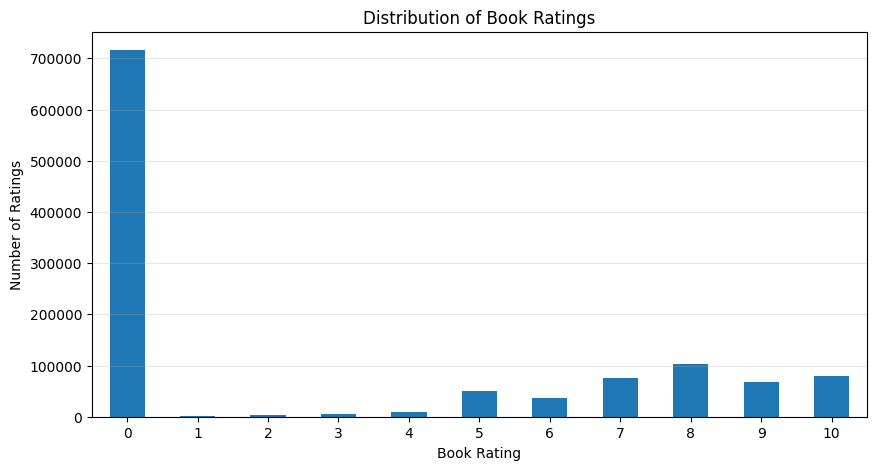

In [13]:
# Convert ratings into numeric values for analysis.
# This is a temporary Series; Bronze data is not modified.

rating_values = pd.to_numeric(
    ratings["Book-Rating"],
    errors="coerce"
)

# Calculate the frequency of each rating

rating_distribution = rating_values.value_counts().sort_index()

print("Rating Distribution:")
display(rating_distribution.to_frame("Number of Ratings"))

# Calculate the number of zero ratings

zero_ratings = (rating_values == 0).sum()

# Calculate the number of explicit ratings from 1 to 10

explicit_ratings = rating_values.between(1, 10).sum()

print("\nNumber of Zero Ratings:", zero_ratings)

print("Number of Explicit Ratings:", explicit_ratings)

# Visualize the rating distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

rating_distribution.plot(kind="bar")

plt.title("Distribution of Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Ratings")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

**Examine user ages and publication years**

USER AGE ANALYSIS

Age Statistics:


,Age
count,168096.000000
mean,34.751434
std,14.428097
min,0.000000
25%,24.000000
50%,32.000000
75%,44.000000
max,244.000000


Missing Ages: 110763
Ages Below 5: 882
Ages Above 100: 366

PUBLICATION YEAR ANALYSIS

Publication Year Statistics:


,Year-Of-Publication
count,255560.000000
mean,1958.462987
std,263.009881
min,0.000000
25%,1989.000000
50%,1995.000000
75%,2000.000000
max,2050.000000


Missing Publication Years: 15819
Publication Year Equal to 0: 4523
Future Publication Years: 8


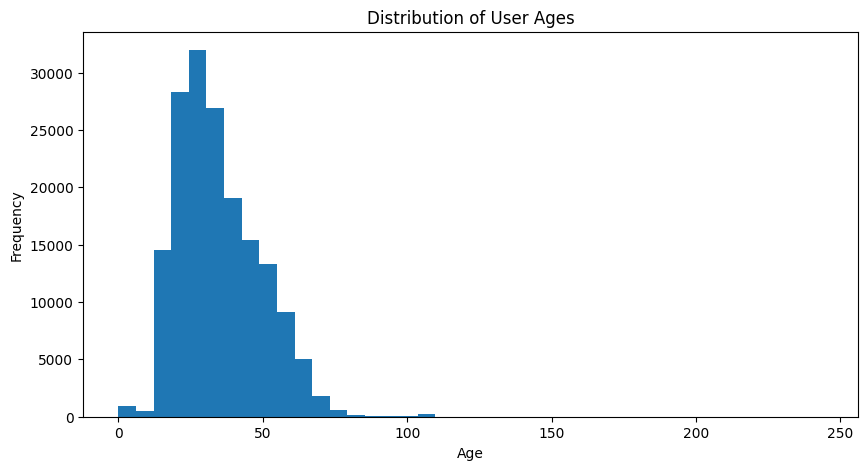

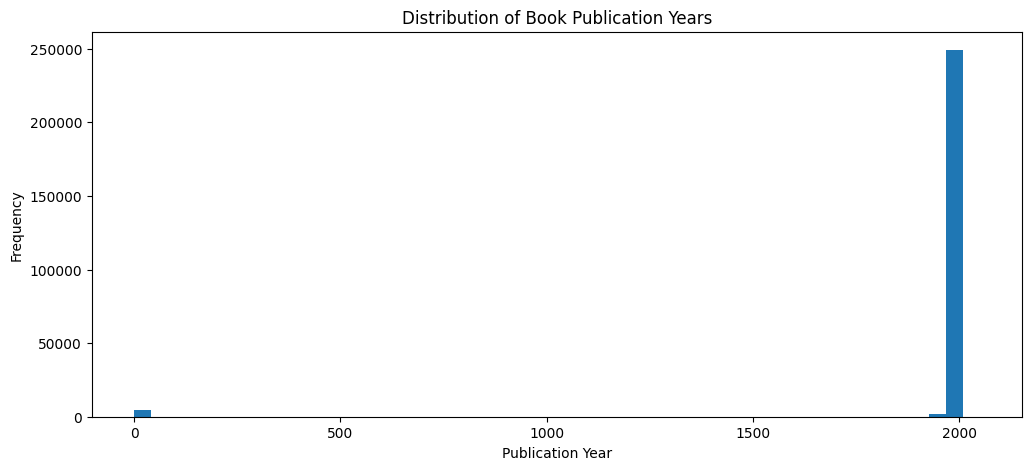

In [14]:
# Convert user ages into numeric values for EDA.

age_values = pd.to_numeric(
    users["Age"],
    errors="coerce"
)

# Convert publication years into numeric values.

publication_years = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

# Get the current year for identifying future publication years.

current_year = datetime.now().year

# Analyze user ages.

print("USER AGE ANALYSIS")

print("\nAge Statistics:")
display(age_values.describe())

print("Missing Ages:", age_values.isnull().sum())

print("Ages Below 5:", (age_values < 5).sum())

print("Ages Above 100:", (age_values > 100).sum())


# Analyze publication years.

print("\nPUBLICATION YEAR ANALYSIS")

print("\nPublication Year Statistics:")
display(publication_years.describe())

print("Missing Publication Years:", publication_years.isnull().sum())

print("Publication Year Equal to 0:",
      (publication_years == 0).sum())

print("Future Publication Years:",
      (publication_years > current_year).sum())


# Visualize user age distribution.

plt.figure(figsize=(10, 5))

age_values.dropna().plot(
    kind="hist",
    bins=40
)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()


# Visualize publication year distribution.

plt.figure(figsize=(12, 5))

publication_years.dropna().plot(
    kind="hist",
    bins=50
)

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Frequency")

plt.show()

### **-> Calculate ratings per user and per book**

RATINGS PER USER


,0
count,105283.000000
mean,10.920851
std,90.562825
min,1.000000
25%,1.000000
50%,1.000000
75%,4.000000
max,13602.000000



RATINGS PER BOOK


,0
count,340556.000000
mean,3.376185
std,12.436252
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,2502.000000


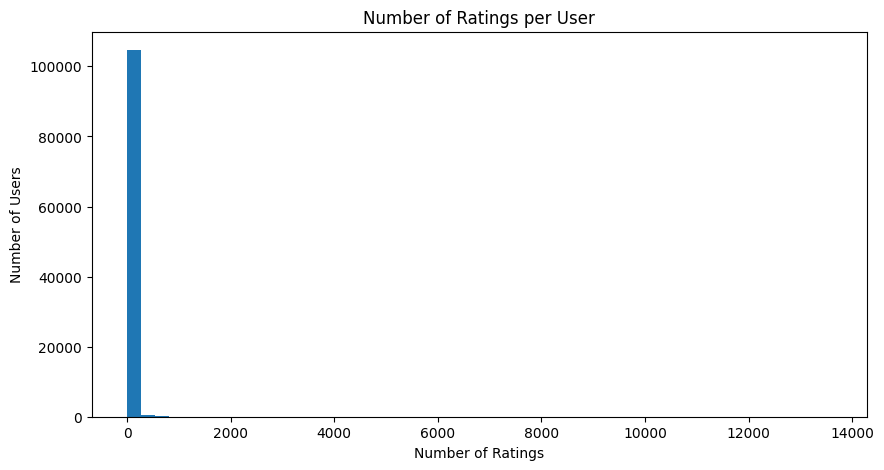

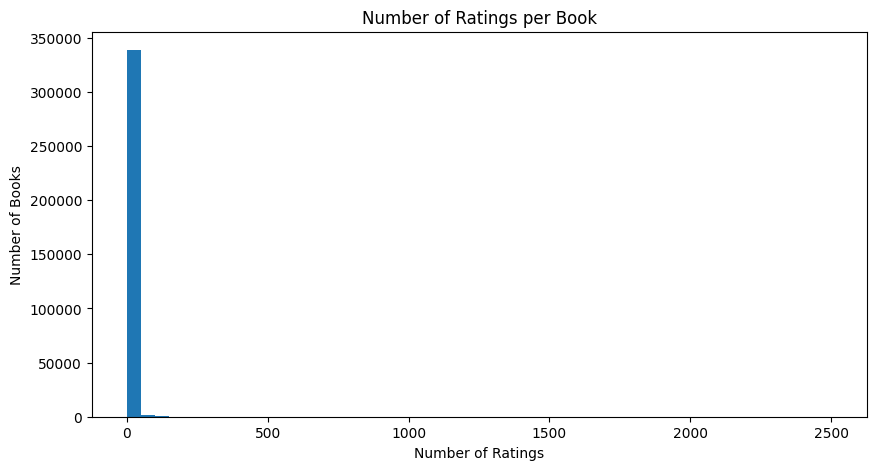

In [15]:
# Calculate the number of ratings received by each user.

ratings_per_user = (
    ratings.groupby("User-ID")
    .size()
)

# Calculate the number of ratings received by each book.

ratings_per_book = (
    ratings.groupby("ISBN")
    .size()
)

# Display statistical summaries.

print("RATINGS PER USER")

display(ratings_per_user.describe())

print("\nRATINGS PER BOOK")

display(ratings_per_book.describe())


# Visualize the number of ratings per user.

plt.figure(figsize=(10, 5))

ratings_per_user.plot(
    kind="hist",
    bins=50
)

plt.title("Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.show()


# Visualize the number of ratings per book.

plt.figure(figsize=(10, 5))

ratings_per_book.plot(
    kind="hist",
    bins=50
)

plt.title("Number of Ratings per Book")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Books")

plt.show()

### **-> Calculate user-book matrix sparsity**

In [16]:
# Calculate the number of unique users.

number_of_users = ratings["User-ID"].nunique()

# Calculate the number of unique books.

number_of_books = ratings["ISBN"].nunique()

# Calculate distinct user-book rating pairs.

actual_ratings = ratings[
    ["User-ID", "ISBN"]
].drop_duplicates().shape[0]

# Calculate the total possible user-book combinations.

total_possible_pairs = number_of_users * number_of_books

# Calculate matrix density.

matrix_density = (
    actual_ratings / total_possible_pairs
)

# Calculate matrix sparsity.

matrix_sparsity = (
    1 - matrix_density
) * 100


# Display the results.

print("USER-BOOK MATRIX SPARSITY ANALYSIS")

print("\nNumber of Users:", number_of_users)

print("Number of Books:", number_of_books)

print("Actual User-Book Ratings:", actual_ratings)

print("Total Possible User-Book Pairs:", total_possible_pairs)

print(f"\nMatrix Density: {matrix_density * 100:.4f}%")

print(f"Matrix Sparsity: {matrix_sparsity:.4f}%")

USER-BOOK MATRIX SPARSITY ANALYSIS

Number of Users: 105283
Number of Books: 340556
Actual User-Book Ratings: 1149780
Total Possible User-Book Pairs: 35854757348

Matrix Density: 0.0032%
Matrix Sparsity: 99.9968%


# **Step 3 — Clean the Data and Build the Silver Layer**

### **-> Load fresh Bronze data**

In [17]:
# Reload the original Bronze tables.
# We start from Bronze so that cleaning never changes the raw data.

users = pd.read_parquet(
    os.path.join(BRONZE_PATH, "users.parquet")
).copy()

books = pd.read_parquet(
    os.path.join(BRONZE_PATH, "books.parquet")
).copy()

ratings = pd.read_parquet(
    os.path.join(BRONZE_PATH, "ratings.parquet")
).copy()

# Remove ingestion_timestamp from the working Silver copies.
# The original timestamp remains preserved in Bronze.

users.drop(columns=["ingestion_timestamp"], inplace=True)

books.drop(columns=["ingestion_timestamp"], inplace=True)

ratings.drop(columns=["ingestion_timestamp"], inplace=True)

# Standardize identifier types to avoid mismatches during joins.

users["User-ID"] = users["User-ID"].astype(str)

books["ISBN"] = books["ISBN"].astype(str)

ratings["User-ID"] = ratings["User-ID"].astype(str)

ratings["ISBN"] = ratings["ISBN"].astype(str)

print("Fresh Bronze data loaded for Silver processing!")

Fresh Bronze data loaded for Silver processing!


### **-> Remove duplicate rows**

In [18]:
# Remove duplicate user records using User-ID.
# Each user should have only one record.

users = users.drop_duplicates(
    subset=["User-ID"],
    keep="first"
).copy()


# Remove duplicate book records using ISBN.
# Each book should have only one record.

books = books.drop_duplicates(
    subset=["ISBN"],
    keep="first"
).copy()


# Remove duplicate ratings using User-ID and ISBN.
# A user should have only one rating record for a particular book.

ratings = ratings.drop_duplicates(
    subset=["User-ID", "ISBN"],
    keep="first"
).copy()


# Display the dataset sizes after duplicate removal.

print("After Removing Duplicates:")

print("Users:", users.shape)

print("Books:", books.shape)

print("Ratings:", ratings.shape)

After Removing Duplicates:
Users: (278859, 3)
Books: (271379, 8)
Ratings: (1149780, 3)


### **-> Remove zero ratings and retain ratings from 1 to 10**

In [19]:
# Convert Book-Rating into numeric values.

ratings["Book-Rating"] = pd.to_numeric(
    ratings["Book-Rating"],
    errors="coerce"
)

# Remove zero ratings because they represent no explicit rating.
# Retain only ratings between 1 and 10.

ratings = ratings[
    ratings["Book-Rating"].between(1, 10)
].copy()

# Convert ratings into integer values.

ratings["Book-Rating"] = ratings[
    "Book-Rating"
].astype(int)


# Verify the remaining rating values.

print("Ratings after removing zero and invalid ratings:")

print(ratings["Book-Rating"].value_counts().sort_index())

print("\nRemaining Ratings:", len(ratings))

Ratings after removing zero and invalid ratings:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Remaining Ratings: 433671


### **-> Clean user ages and fill missing values with median**

In [20]:
# Convert the Age column into numeric values.
# Invalid values will become NaN.

users["Age"] = pd.to_numeric(
    users["Age"],
    errors="coerce"
)

# Set ages below 5 or above 100 to missing values.

users.loc[
    (users["Age"] < 5) | (users["Age"] > 100),
    "Age"
] = np.nan

# Calculate the median age from valid age values.

median_age = users["Age"].median()

# Fill all missing ages with the median.

if pd.isna(median_age):
    raise ValueError("No valid ages available to calculate the median.")

users["Age"] = users["Age"].fillna(median_age)

# Convert age into integer values.

users["Age"] = users["Age"].round().astype(int)


# Verify age cleaning.

print("Median Age:", median_age)

print("Missing Ages:", users["Age"].isnull().sum())

print("\nAge Statistics:")
display(users["Age"].describe())

Median Age: 32.0
Missing Ages: 0

Age Statistics:


,Age
count,278859.000000
mean,33.643379
std,10.630961
min,5.000000
25%,29.000000
50%,32.000000
75%,35.000000
max,100.000000


### **-> Split Location into city, state and country**

In [21]:
# Replace missing locations with empty strings.

users["Location"] = (
    users["Location"]
    .fillna("")
    .astype(str)
)

# Split the Location column into three parts.
# maxsplit=2 ensures the remaining text stays in the country field.

location_parts = users["Location"].str.split(
    ",",
    n=2,
    expand=True
)

# Ensure that all three output columns exist.

location_parts = location_parts.reindex(
    columns=[0, 1, 2]
)

# Create separate City, State and Country columns.

users["City"] = location_parts[0].fillna("").str.strip()

users["State"] = location_parts[1].fillna("").str.strip()

users["Country"] = location_parts[2].fillna("").str.strip()

# Remove the original Location column.

users.drop(
    columns=["Location"],
    inplace=True
)

# Display the new columns.

display(
    users[["City", "State", "Country"]].head(10)
)

print("Location successfully split into three columns!")

,City,State,Country
0,nyc,new york,usa
1,stockton,california,usa
2,moscow,yukon territory,russia
3,porto,v.n.gaia,portugal
4,farnborough,hants,united kingdom
5,santa monica,california,usa
6,washington,dc,usa
7,timmins,ontario,canada
8,germantown,tennessee,usa
9,albacete,wisconsin,spain


Location successfully split into three columns!


### **-> Fix book publication years**

In [22]:
# Convert publication year into numeric values.
# Non-numeric values will become missing.

books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

# Get the current year.

current_year = datetime.now().year

# Identify invalid publication years.
# Year 0 and future years are considered invalid.

invalid_years = (
    (books["Year-Of-Publication"] == 0) |
    (books["Year-Of-Publication"] > current_year)
)

# Replace invalid years with NaN.

books.loc[
    invalid_years,
    "Year-Of-Publication"
] = np.nan

# Verify the cleaned publication years.

print("Current Year:", current_year)

print(
    "Missing/Invalid Publication Years:",
    books["Year-Of-Publication"].isnull().sum()
)

print("\nPublication Year Statistics:")

display(books["Year-Of-Publication"].describe())

Current Year: 2026
Missing/Invalid Publication Years: 20350

Publication Year Statistics:


,Year-Of-Publication
count,251029.000000
mean,1993.747786
std,8.274868
min,1376.000000
25%,1989.000000
50%,1996.000000
75%,2000.000000
max,2026.000000


### **-> Clean text columns and remove image URL columns**

In [23]:
# Define a function to remove extra spaces and standardize text case.

def clean_text_columns(df, columns):

    for column in columns:

        if column in df.columns:

            df[column] = (
                df[column]
                .astype("string")
                .str.strip()
                .str.title()
            )

    return df


# Clean user location columns.

users = clean_text_columns(
    users,
    ["City", "State", "Country"]
)


# Clean book text columns.

books = clean_text_columns(
    books,
    ["Book-Title", "Book-Author", "Publisher"]
)


# Identify unnecessary image URL columns.

image_columns = [
    column for column in books.columns
    if column.lower().startswith("image-url")
]


# Remove image URL columns.

books.drop(
    columns=image_columns,
    inplace=True
)


# Display the final columns.

print("Removed Image URL Columns:", image_columns)

print("\nRemaining Book Columns:")

print(books.columns.tolist())

print("\nCleaned Books:")

display(books.head())

Removed Image URL Columns: ['Image-URL-S', 'Image-URL-M', 'Image-URL-L']

Remaining Book Columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher']

Cleaned Books:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002.0,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001.0,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'Este,1991.0,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999.0,Farrar Straus Giroux
4,0393045218,"The Mummies Of Urumchi"";""E. J. W. Barber",1999,NaN,Company


### **-> Keep only ratings whose users and books exist**

In [24]:
# Get all valid user IDs from the Users table.

valid_user_ids = set(
    users["User-ID"]
)


# Get all valid ISBN values from the Books table.

valid_book_ids = set(
    books["ISBN"]
)


# Keep only ratings whose user and book exist.

ratings = ratings[
    ratings["User-ID"].isin(valid_user_ids) &
    ratings["ISBN"].isin(valid_book_ids)
].copy()


# Verify referential integrity.

print("Ratings after referential integrity filtering:")

print("Remaining Ratings:", ratings.shape)

print(
    "Invalid User References:",
    (~ratings["User-ID"].isin(valid_user_ids)).sum()
)

print(
    "Invalid Book References:",
    (~ratings["ISBN"].isin(valid_book_ids)).sum()
)

Ratings after referential integrity filtering:
Remaining Ratings: (383852, 3)
Invalid User References: 0
Invalid Book References: 0


### **-> Apply minimum rating threshold**

In [25]:
# Define the minimum number of ratings required.

MIN_RATINGS = 10

# Iteratively filter users and books until the dataset stabilizes.

iteration = 0

while True:

    iteration += 1

    # Store the previous number of ratings.

    previous_count = len(ratings)


    # Calculate ratings per user.

    user_counts = ratings.groupby("User-ID").size()

    # Keep users having at least 10 ratings.

    active_users = user_counts[
        user_counts >= MIN_RATINGS
    ].index

    ratings = ratings[
        ratings["User-ID"].isin(active_users)
    ].copy()


    # Calculate ratings per book.

    book_counts = ratings.groupby("ISBN").size()

    # Keep books having at least 10 ratings.

    active_books = book_counts[
        book_counts >= MIN_RATINGS
    ].index

    ratings = ratings[
        ratings["ISBN"].isin(active_books)
    ].copy()


    # Display progress.

    print(
        f"Iteration {iteration}: "
        f"{len(ratings)} ratings, "
        f"{ratings['User-ID'].nunique()} users, "
        f"{ratings['ISBN'].nunique()} books"
    )


    # Stop when no more ratings are removed.

    if len(ratings) == previous_count:
        break


# Retain only users and books present in the final ratings table.

users = users[
    users["User-ID"].isin(ratings["User-ID"].unique())
].copy()

books = books[
    books["ISBN"].isin(ratings["ISBN"].unique())
].copy()


# Verify minimum rating conditions.

assert ratings.groupby("User-ID").size().min() >= MIN_RATINGS

assert ratings.groupby("ISBN").size().min() >= MIN_RATINGS


# Display final Silver dataset dimensions.

print("\nFINAL SILVER DATASET")

print("Users:", users.shape)

print("Books:", books.shape)

print("Ratings:", ratings.shape)

print(
    "\nMinimum ratings per user:",
    ratings.groupby("User-ID").size().min()
)

print(
    "Minimum ratings per book:",
    ratings.groupby("ISBN").size().min()
)

Iteration 1: 72059 ratings, 6117 users, 3276 books
Iteration 2: 46703 ratings, 2217 users, 2248 books
Iteration 3: 42548 ratings, 1896 users, 2077 books
Iteration 4: 41690 ratings, 1835 users, 2041 books
Iteration 5: 41501 ratings, 1823 users, 2032 books
Iteration 6: 41456 ratings, 1820 users, 2030 books
Iteration 7: 41456 ratings, 1820 users, 2030 books

FINAL SILVER DATASET
Users: (1820, 5)
Books: (2030, 5)
Ratings: (41456, 3)

Minimum ratings per user: 10
Minimum ratings per book: 10


### **-> Save cleaned tables to Silver layer**

In [26]:
# Save cleaned Users data into Silver.

users.to_parquet(
    os.path.join(SILVER_PATH, "users.parquet"),
    index=False
)


# Save cleaned Books data into Silver.

books.to_parquet(
    os.path.join(SILVER_PATH, "books.parquet"),
    index=False
)


# Save cleaned Ratings data into Silver.

ratings.to_parquet(
    os.path.join(SILVER_PATH, "ratings.parquet"),
    index=False
)


print("All cleaned datasets saved successfully in Silver layer!")

print("\nSilver Files:")

print(os.listdir(SILVER_PATH))

All cleaned datasets saved successfully in Silver layer!

Silver Files:
['books.parquet', 'ratings.parquet', 'users.parquet']


### **-> Verify Silver layer**

In [27]:
# Read all cleaned Parquet files from Silver.

silver_users = pd.read_parquet(
    os.path.join(SILVER_PATH, "users.parquet")
)

silver_books = pd.read_parquet(
    os.path.join(SILVER_PATH, "books.parquet")
)

silver_ratings = pd.read_parquet(
    os.path.join(SILVER_PATH, "ratings.parquet")
)


# Display final shapes.

print("=" * 50)
print("SILVER LAYER VERIFICATION")
print("=" * 50)

print("\nUsers:", silver_users.shape)

print("Books:", silver_books.shape)

print("Ratings:", silver_ratings.shape)


# Verify that there are no zero ratings.

print(
    "\nZero Ratings Remaining:",
    (silver_ratings["Book-Rating"] == 0).sum()
)


# Verify age cleaning.

print(
    "Missing Ages:",
    silver_users["Age"].isnull().sum()
)


# Verify minimum rating threshold.

print(
    "Minimum User Ratings:",
    silver_ratings.groupby("User-ID").size().min()
)

print(
    "Minimum Book Ratings:",
    silver_ratings.groupby("ISBN").size().min()
)


print("\nSilver layer verification completed!")

SILVER LAYER VERIFICATION

Users: (1820, 5)
Books: (2030, 5)
Ratings: (41456, 3)

Zero Ratings Remaining: 0
Missing Ages: 0
Minimum User Ratings: 10
Minimum Book Ratings: 10

Silver layer verification completed!


# **Step 4 — Build the Gold Layer**

### **-> Load Silver tables**

In [28]:
# Load the cleaned datasets from the Silver layer.

users = pd.read_parquet(
    os.path.join(SILVER_PATH, "users.parquet")
)

books = pd.read_parquet(
    os.path.join(SILVER_PATH, "books.parquet")
)

ratings = pd.read_parquet(
    os.path.join(SILVER_PATH, "ratings.parquet")
)

print("Silver datasets loaded successfully!")

print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Silver datasets loaded successfully!
Users: (1820, 5)
Books: (2030, 5)
Ratings: (41456, 3)


### **-> Create user and book index mappings**

In [29]:
# Create a list of all unique book ISBNs.

book_ids = books["ISBN"].tolist()

# Create a list of all unique user IDs.

user_ids = users["User-ID"].tolist()


# Create a mapping from ISBN to matrix row index.

book_to_idx = {
    book_id: index
    for index, book_id in enumerate(book_ids)
}


# Create a mapping from User-ID to matrix column index.

user_to_idx = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}


# Display mapping information.

print("Book mappings created:", len(book_to_idx))

print("User mappings created:", len(user_to_idx))

print("\nSample Book Mapping:")

print(list(book_to_idx.items())[:5])

print("\nSample User Mapping:")

print(list(user_to_idx.items())[:5])

Book mappings created: 2030
User mappings created: 1820

Sample Book Mapping:
[('0440234743', 0), ('0452264464', 1), ('0971880107', 2), ('0345402871', 3), ('0345417623', 4)]

Sample User Mapping:
[('243', 0), ('254', 1), ('638', 2), ('805', 3), ('882', 4)]


### **-> Create the sparse user-book rating matrix**

In [30]:
# Import the CSR sparse matrix implementation.

from scipy.sparse import csr_matrix

# Convert ISBN values into their corresponding matrix row indices.

row_indices = ratings["ISBN"].map(book_to_idx).values

# Convert User-ID values into their corresponding matrix column indices.

col_indices = ratings["User-ID"].map(user_to_idx).values

# Extract actual book ratings.

rating_values = ratings["Book-Rating"].values


# Create the sparse rating matrix.
# Rows represent books.
# Columns represent users.
# Values represent explicit ratings.

rating_matrix = csr_matrix(
    (
        rating_values,
        (row_indices, col_indices)
    ),
    shape=(len(book_ids), len(user_ids)),
    dtype=np.float32
)


# Display matrix information.

print("Sparse Rating Matrix Created Successfully!")

print("\nMatrix Shape:", rating_matrix.shape)

print("Number of Stored Ratings:", rating_matrix.nnz)

print("Matrix Type:", type(rating_matrix))

print("Matrix Density:",
      rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1]) * 100,
      "%")

Sparse Rating Matrix Created Successfully!

Matrix Shape: (2030, 1820)
Number of Stored Ratings: 41456
Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>
Matrix Density: 1.1220700481784225 %


### **-> Create the book lookup table**

In [31]:
# Create a lookup table containing book ID, title and author.
# This table will be used to display readable recommendations.

book_lookup = books[
    ["ISBN", "Book-Title", "Book-Author"]
].copy()


# Rename columns for easier usage.

book_lookup.columns = [
    "book_id",
    "title",
    "author"
]


# Display the book lookup table.

print("Book Lookup Table Created Successfully!")

display(book_lookup.head(10))

Book Lookup Table Created Successfully!


,book_id,title,author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,Michael Crichton
5,0446310786,"To Kill A Mockingbird"";""Harper Lee",1988
6,0449005615,Seabiscuit: An American Legend,Laura Hillenbrand
7,0671888587,I'Ll Be Seeing You,Mary Higgins Clark
8,0553582747,From The Corner Of His Eye,Dean Koontz
9,0425182908,Isle Of Dogs,Patricia Cornwell


### **-> Create user-level aggregates**

In [32]:
# Calculate the average rating and total number of ratings
# provided by each user.

user_aggregates = (
    ratings.groupby("User-ID")
    .agg(
        average_rating=("Book-Rating", "mean"),
        number_of_ratings=("Book-Rating", "count")
    )
    .reset_index()
)


# Display user-level aggregates.

print("User-Level Aggregates Created Successfully!")

display(user_aggregates.head(10))

User-Level Aggregates Created Successfully!


,User-ID,average_rating,number_of_ratings
0,100088,9.384615,13
1,100227,9.000000,13
2,100264,7.916667,12
3,10030,9.400000,10
4,100459,8.369565,46
5,100644,8.470588,17
6,100846,7.793103,29
7,100906,8.311475,61
8,101209,6.933333,15
9,101304,9.416667,12


### **-> Create book-level aggregates**

In [33]:
# Calculate the average rating and total number of ratings
# received by each book.

book_aggregates = (
    ratings.groupby("ISBN")
    .agg(
        average_rating=("Book-Rating", "mean"),
        number_of_ratings=("Book-Rating", "count")
    )
    .reset_index()
)


# Display book-level aggregates.

print("Book-Level Aggregates Created Successfully!")

display(book_aggregates.head(10))

Book-Level Aggregates Created Successfully!


,ISBN,average_rating,number_of_ratings
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11
5,006000438X,7.277778,18
6,0060008032,7.388889,18
7,006001203X,8.090909,11
8,0060085444,7.083333,12
9,0060085452,8.111111,18


### **-> Save all Gold layer data**

In [34]:
# Import functions to save sparse matrices.

from scipy.sparse import save_npz

# Save the sparse user-book rating matrix.

save_npz(
    os.path.join(GOLD_PATH, "rating_matrix.npz"),
    rating_matrix
)


# Save the book lookup table.

book_lookup.to_parquet(
    os.path.join(GOLD_PATH, "book_lookup.parquet"),
    index=False
)


# Save user-level aggregates.

user_aggregates.to_parquet(
    os.path.join(GOLD_PATH, "user_aggregates.parquet"),
    index=False
)


# Save book-level aggregates.

book_aggregates.to_parquet(
    os.path.join(GOLD_PATH, "book_aggregates.parquet"),
    index=False
)


# Save user index mappings.

user_index_df = pd.DataFrame({
    "User-ID": user_ids,
    "matrix_index": range(len(user_ids))
})

user_index_df.to_parquet(
    os.path.join(GOLD_PATH, "user_index.parquet"),
    index=False
)


# Save book index mappings.

book_index_df = pd.DataFrame({
    "ISBN": book_ids,
    "matrix_index": range(len(book_ids))
})

book_index_df.to_parquet(
    os.path.join(GOLD_PATH, "book_index.parquet"),
    index=False
)


print("All Gold layer files saved successfully!")

print("\nGold Files:")

print(os.listdir(GOLD_PATH))

All Gold layer files saved successfully!

Gold Files:
['user_index.parquet', 'book_aggregates.parquet', 'book_index.parquet', 'book_lookup.parquet', 'rating_matrix.npz', 'user_aggregates.parquet']


### **-> Verify Gold layer**

In [35]:
# Import the function required to load sparse matrices.

from scipy.sparse import load_npz

# Load the saved sparse matrix.

verified_matrix = load_npz(
    os.path.join(GOLD_PATH, "rating_matrix.npz")
)

# Load all Gold layer tables.

verified_lookup = pd.read_parquet(
    os.path.join(GOLD_PATH, "book_lookup.parquet")
)

verified_user_aggregates = pd.read_parquet(
    os.path.join(GOLD_PATH, "user_aggregates.parquet")
)

verified_book_aggregates = pd.read_parquet(
    os.path.join(GOLD_PATH, "book_aggregates.parquet")
)


# Display verification results.

print("=" * 50)
print("GOLD LAYER VERIFICATION")
print("=" * 50)

print("\nRating Matrix Shape:", verified_matrix.shape)

print("Stored Ratings:", verified_matrix.nnz)

print("\nBook Lookup Shape:", verified_lookup.shape)

print("User Aggregates Shape:", verified_user_aggregates.shape)

print("Book Aggregates Shape:", verified_book_aggregates.shape)

print("\nGold layer verification completed successfully!")

GOLD LAYER VERIFICATION

Rating Matrix Shape: (2030, 1820)
Stored Ratings: 41456

Book Lookup Shape: (2030, 3)
User Aggregates Shape: (1820, 3)
Book Aggregates Shape: (2030, 3)

Gold layer verification completed successfully!


# **Step 5 — Build the Recommender (Item-Based Collaborative Filtering)**

### **-> Load Gold data for the recommender**

In [36]:
# Load the Gold sparse rating matrix.

rating_matrix = load_npz(
    os.path.join(GOLD_PATH, "rating_matrix.npz")
)

# Load the book lookup table.

book_lookup = pd.read_parquet(
    os.path.join(GOLD_PATH, "book_lookup.parquet")
)

# Load user and book index mappings.

user_index_df = pd.read_parquet(
    os.path.join(GOLD_PATH, "user_index.parquet")
)

book_index_df = pd.read_parquet(
    os.path.join(GOLD_PATH, "book_index.parquet")
)

# Load user and book aggregates.

user_aggregates = pd.read_parquet(
    os.path.join(GOLD_PATH, "user_aggregates.parquet")
)

book_aggregates = pd.read_parquet(
    os.path.join(GOLD_PATH, "book_aggregates.parquet")
)


# Reconstruct mappings in their original matrix order.

user_ids = (
    user_index_df.sort_values("matrix_index")["User-ID"].tolist()
)

book_ids = (
    book_index_df.sort_values("matrix_index")["ISBN"].tolist()
)

user_to_idx = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}

book_to_idx = {
    book_id: index
    for index, book_id in enumerate(book_ids)
}


print("Gold data loaded successfully!")

print("Rating Matrix:", rating_matrix.shape)

print("Users:", len(user_ids))

print("Books:", len(book_ids))

Gold data loaded successfully!
Rating Matrix: (2030, 1820)
Users: 1820
Books: 2030


### **-> Calculate cosine similarity using NearestNeighbors**

In [37]:
# Import NearestNeighbors from Scikit-learn.

from sklearn.neighbors import NearestNeighbors

# Create a NearestNeighbors model.
# Each row of the matrix represents a book.
# Cosine distance is used to identify similar books.

neighbor_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

# Train the model using the sparse rating matrix.

neighbor_model.fit(rating_matrix)

print("NearestNeighbors model trained successfully!")

print("Similarity Metric: Cosine Similarity")

NearestNeighbors model trained successfully!
Similarity Metric: Cosine Similarity


### **-> Create find_similar_books() function**

In [38]:
# Define a function that accepts a book title
# and returns the 10 most similar books.

def find_similar_books(book_title, n=10):

    # Search for the given book title.
    matching_books = book_lookup[
        book_lookup["title"].fillna("").str.casefold()
        == str(book_title).strip().casefold()
    ].copy()

    # Check whether the book exists.
    if matching_books.empty:

        print("Book not found:", book_title)

        return pd.DataFrame(
            columns=["book_id", "title", "author", "similarity"]
        )

    # If multiple books have the same title,
    # choose the ISBN with the highest number of ratings.

    matching_books = matching_books.merge(
        book_aggregates,
        left_on="book_id",
        right_on="ISBN",
        how="left"
    )

    matching_books = matching_books.sort_values(
        "number_of_ratings",
        ascending=False
    )

    selected_book_id = matching_books.iloc[0]["book_id"]

    # Get the matrix index of the selected book.

    book_idx = book_to_idx[selected_book_id]

    # Find the nearest books.
    # n+1 is used because the original book itself is included.

    neighbors_count = min(n + 1, len(book_ids))

    distances, indices = neighbor_model.kneighbors(
        rating_matrix.getrow(book_idx),
        n_neighbors=neighbors_count
    )

    results = []

    # Convert cosine distance into cosine similarity.

    for distance, index in zip(distances[0], indices[0]):

        # Skip the original book.

        if index == book_idx:
            continue

        similarity = 1 - distance

        similar_book_id = book_ids[index]

        # Retrieve readable book information.

        book_info = book_lookup[
            book_lookup["book_id"] == similar_book_id
        ]

        if not book_info.empty:

            results.append({
                "book_id": similar_book_id,
                "title": book_info.iloc[0]["title"],
                "author": book_info.iloc[0]["author"],
                "similarity": round(float(similarity), 4)
            })

    return pd.DataFrame(results).head(n)

### **-> Test similar book recommendations**

In [39]:
# Select an actual book title from the lookup table.

sample_book_title = book_lookup.iloc[0]["title"]

print("Original Book:", sample_book_title)

# Find the 10 most similar books.

similar_books = find_similar_books(
    sample_book_title,
    n=10
)

print("\n10 Most Similar Books:")

display(similar_books)

Original Book: The Testament

10 Most Similar Books:


,book_id,title,author,similarity
0,0345413873,Monster : A Novel (Alex Delaware Novels (Paper...,Jonathan Kellerman,0.2528
1,0440221471,The Runaway Jury,John Grisham,0.2378
2,0451188454,The Bone Collector (Lincoln Rhyme Novels (Pape...,Jeff Deaver,0.2376
3,1559029838,Call Of The Wild,Jack London,0.2359
4,0446607711,The Simple Truth,David Baldacci,0.2356
5,0440225701,The Street Lawyer,John Grisham,0.2198
6,0425177173,Atlantis Found,Clive Cussler,0.1994
7,042510687X,Outbreak,Robin Cook,0.1987
8,0425154092,From Potter'S Field,Patricia Daniels Cornwell,0.1962
9,0440236053,Writ Of Execution,Perri O'Shaughnessy,0.1901


### **-> Implement personalized recommend() function**

In [40]:
# Create a personalized recommendation function.
#
# Steps:
# 1. Identify books rated highly by the user.
# 2. Find books similar to those highly rated books.
# 3. Weight similarity using the user's rating.
# 4. Exclude books the user has already rated.
# 5. Rank candidates and return the top n books.

def recommend(user_id, n=10):

    # Verify that the user exists in the Gold matrix.

    if user_id not in user_to_idx:

        print("User not found:", user_id)

        return pd.DataFrame(
            columns=[
                "book_id",
                "title",
                "author",
                "recommendation_score"
            ]
        )


    # Get the matrix column corresponding to the user.

    user_idx = user_to_idx[user_id]

    # Extract all ratings given by this user.

    user_ratings = (
        rating_matrix[:, user_idx]
        .toarray()
        .flatten()
    )


    # Identify books already rated by the user.

    already_read = set(
        np.where(user_ratings > 0)[0]
    )


    # Find books rated 7 or higher.

    high_rated_books = np.where(
        user_ratings >= 7
    )[0]


    # If the user has no ratings of 7 or above,
    # use their five highest-rated books instead.

    if len(high_rated_books) == 0:

        rated_books = np.where(
            user_ratings > 0
        )[0]

        if len(rated_books) == 0:

            print("This user has no ratings!")

            return pd.DataFrame()

        sorted_ratings = rated_books[
            np.argsort(user_ratings[rated_books])[::-1]
        ]

        high_rated_books = sorted_ratings[:5]


    # Store recommendation scores for candidate books.

    recommendation_scores = {}


    # Find books similar to every highly rated book.

    for book_idx in high_rated_books:

        # Get the user's rating for the selected book.

        user_rating = user_ratings[book_idx]

        # Find the 10 nearest books.

        distances, indices = neighbor_model.kneighbors(
            rating_matrix.getrow(book_idx),
            n_neighbors=min(11, len(book_ids))
        )


        # Calculate weighted similarity scores.

        for distance, similar_idx in zip(
            distances[0],
            indices[0]
        ):

            similarity = 1 - distance

            # Exclude books already read by the user.

            if similar_idx in already_read:
                continue

            # Ignore non-positive similarity.

            if similarity <= 0:
                continue

            # Weight similarity according to the user's rating.

            score = similarity * user_rating

            recommendation_scores[similar_idx] = (
                recommendation_scores.get(similar_idx, 0) + score
            )


    # Sort books by recommendation score in descending order.

    ranked_books = sorted(
        recommendation_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )


    # Convert recommended matrix indices into readable book titles.

    results = []

    for book_idx, score in ranked_books[:n]:

        recommended_book_id = book_ids[book_idx]

        book_info = book_lookup[
            book_lookup["book_id"] == recommended_book_id
        ]

        if not book_info.empty:

            results.append({
                "book_id": recommended_book_id,
                "title": book_info.iloc[0]["title"],
                "author": book_info.iloc[0]["author"],
                "recommendation_score": round(float(score), 4)
            })


    return pd.DataFrame(results)

# **Step 6 — Demo and Sanity Check**

### **-> Select three different users**

In [41]:
# Load the cleaned ratings from the Silver layer.

silver_ratings = pd.read_parquet(
    os.path.join(SILVER_PATH, "ratings.parquet")
)

# Find users who have given ratings of 7 or higher.

high_rating_users = silver_ratings[
    silver_ratings["Book-Rating"] >= 7
]

# Count the number of highly rated books for each user.

user_high_rating_counts = (
    high_rating_users.groupby("User-ID")
    .size()
    .sort_values(ascending=False)
)

# Select three different users from the Gold matrix.

demo_users = [
    user_id
    for user_id in user_high_rating_counts.index
    if user_id in user_to_idx
][:3]

# Verify that three users have been selected.

assert len(demo_users) == 3, "Three demo users could not be selected."

print("Selected Three Demo Users:")

for user_id in demo_users:
    print("User ID:", user_id)

Selected Three Demo Users:
User ID: 11676
User ID: 16795
User ID: 104636


### **-> Display highly rated books and recommendations**

In [42]:
# Run the recommendation system for three different users.
# Display their highly rated books and recommended books separately.

for user_id in demo_users:

    print("\n" + "=" * 80)

    print("USER ID:", user_id)

    print("=" * 80)


    # Find books rated 7 or higher by this user.

    liked_books = silver_ratings[
        (silver_ratings["User-ID"] == user_id) &
        (silver_ratings["Book-Rating"] >= 7)
    ].sort_values(
        "Book-Rating",
        ascending=False
    )


    # Merge ratings with book information to display readable titles.

    liked_books = liked_books.merge(
        book_lookup,
        left_on="ISBN",
        right_on="book_id",
        how="left"
    )


    print("\nBOOKS RATED HIGHLY BY THE USER:")

    display(
        liked_books[
            ["title", "author", "Book-Rating"]
        ].head(10)
    )


    # Generate personalized recommendations.

    recommendations = recommend(
        user_id,
        n=10
    )


    print("\nTOP 10 RECOMMENDED BOOKS:")

    display(recommendations)


USER ID: 11676

BOOKS RATED HIGHLY BY THE USER:


,title,author,Book-Rating
0,The Time Traveler'S Wife,Audrey Niffenegger,10
1,The Time Traveler'S Wife (Today Show Book Club...,Audrey Niffenegger,10
2,Message From Nam,Danielle Steel,10
3,Mixed Blessings,Danielle Steel,10
4,Echoes,Maeve Binchy,10
5,Remembrance,Danielle Steel,10
6,Illusions: The Adventures Of A Reluctant Messiah,Richard Bach,10
7,The Alchemist: A Fable About Following Your Dream,Paulo Coelho,10
8,The Secret Garden,Frances Hodgson Burnett,10
9,The Reptile Room (A Series Of Unfortunate Even...,Lemony Snicket,10



TOP 10 RECOMMENDED BOOKS:


,book_id,title,author,recommendation_score
0,0440167531,Palomino,Danielle Steel,36.8367
1,0373270976,"Night Shield (Intimate Moments, 1027)",Nora Roberts,31.6602
2,0842332251,The Mark: The Beast Rules The World (Left Behi...,Tim Lahaye,23.2592
3,0842329285,The Indwelling: The Beast Takes Possession (Le...,Tim Lahaye,22.0152
4,0670839531,Needful Things: The Last Castle Rock Story,Stephen King,21.2773
5,0439136350,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,21.1420
6,0399149848,Birthright,Nora Roberts,21.0330
7,0440168724,A Perfect Stranger,Danielle Steel,21.0125
8,043935806X,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,20.3768
9,0842329269,Apollyon: The Destroyer Is Unleashed (Left Beh...,Jerry Jenkins,19.8089



USER ID: 16795

BOOKS RATED HIGHLY BY THE USER:


,title,author,Book-Rating
0,The Dive From Clausen'S Pier (Alex Awards),Ann Packer,10
1,How Reading Changed My Life (Library Of Contem...,Anna Quindlen,10
2,The Lovely Bones: A Novel,Alice Sebold,10
3,The Dogs Of Babel (Today Show Book Club #12),Carolyn Parkhurst,10
4,The Secret Life Of Bees,Sue Monk Kidd,10
5,Life Of Pi,Yann Martel,10
6,The Samurai'S Garden : A Novel,Gail Tsukiyama,10
7,The Liar'S Club: A Memoir,Mary Karr,10
8,Skipping Christmas,John Grisham,10
9,Skipping Christmas,John Grisham,10


... (2 outputs left out)


USER ID: 104636

BOOKS RATED HIGHLY BY THE USER:


,title,author,Book-Rating
0,Where The Sidewalk Ends : Poems And Drawings,Shel Silverstein,10
1,Bridge To Terabithia,Katherine Paterson,10
2,"The Lion, The Witch, And The Wardrobe (The Chr...",C. S. Lewis,10
3,Little House On The Prairie,Laura Ingalls Wilder,10
4,Charlotte'S Web (Trophy Newbery),E. B. White,10
5,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,10
6,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,10
7,Secrets,Danielle Steel,10
8,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,10
9,Eyes Of A Child,Richard North Patterson,10



TOP 10 RECOMMENDED BOOKS:


,book_id,title,author,recommendation_score
0,0671701231,The Anastasia Syndrome,Mary Higgins Clark,24.7621
1,042511984X,The Face Of Fear,Dean R. Koontz,20.5438
2,0312983867,Hard Eight : A Stephanie Plum Novel (A Stephan...,Janet Evanovich,17.5934
3,0312265867,To The Nines: A Stephanie Plum Novel,Janet Evanovich,15.3307
4,0553285785,Public Secrets,Nora Roberts,13.9380
5,0440221471,The Runaway Jury,John Grisham,11.4459
6,038531292X,The Gift,Danielle Steel,11.0974
7,043935806X,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,9.9139
8,0671729454,If There Be Thorns (Dollanganger),V.C. Andrews,9.0601
9,0380732661,The Ritual Bath (Peter Decker &Amp; Rina Lazar...,Faye Kellerman,8.7857


### **-> Perform sanity checks**

In [43]:
# Verify that the recommendation system works correctly.
#
# Check 1: Recommended books should not have been rated by the user.
# Check 2: Recommended books should have readable titles.
# Check 3: Recommendations should be generated for all three users.

for user_id in demo_users:

    # Generate recommendations.

    recommendations = recommend(
        user_id,
        n=10
    )


    # Get the books already rated by the user.

    already_read = set(
        silver_ratings.loc[
            silver_ratings["User-ID"] == user_id,
            "ISBN"
        ]
    )


    # Get the recommended book IDs.

    recommended_ids = set(
        recommendations["book_id"]
    ) if not recommendations.empty else set()


    # Check whether any already-read book was recommended.

    overlap = already_read.intersection(
        recommended_ids
    )


    # Verify that no previously rated book is recommended.

    assert len(overlap) == 0, (
        f"Previously rated books recommended to user {user_id}"
    )


    # Verify that recommended titles are available.

    if not recommendations.empty:

        assert recommendations["title"].notna().all()

        assert recommendations["title"].str.strip().ne("").all()


    # Display verification results.

    print("\nUser ID:", user_id)

    print("Recommendations Generated:", len(recommendations))

    print("Already Rated Books Recommended:", len(overlap))


print("\nAll sanity checks completed successfully!")


User ID: 11676
Recommendations Generated: 10
Already Rated Books Recommended: 0

User ID: 16795
Recommendations Generated: 10
Already Rated Books Recommended: 0

User ID: 104636
Recommendations Generated: 10
Already Rated Books Recommended: 0

All sanity checks completed successfully!


### **-> Verify the complete Data Lake structure**

In [44]:
# Display all files generated in Bronze, Silver and Gold.

print("=" * 60)
print("FINAL DATA LAKE STRUCTURE")
print("=" * 60)


# Display Bronze files.

print("\nBRONZE LAYER:")

for file in sorted(os.listdir(BRONZE_PATH)):
    print(file)


# Display Silver files.

print("\nSILVER LAYER:")

for file in sorted(os.listdir(SILVER_PATH)):
    print(file)


# Display Gold files.

print("\nGOLD LAYER:")

for file in sorted(os.listdir(GOLD_PATH)):
    print(file)


print("\nComplete Data Lake structure verified!")

FINAL DATA LAKE STRUCTURE

BRONZE LAYER:
books.parquet
ratings.parquet
users.parquet

SILVER LAYER:
books.parquet
ratings.parquet
users.parquet

GOLD LAYER:
book_aggregates.parquet
book_index.parquet
book_lookup.parquet
rating_matrix.npz
user_aggregates.parquet
user_index.parquet

Complete Data Lake structure verified!


### **-> Create ZIP file for submission**

In [45]:
# Create a ZIP archive containing all three Data Lake layers.
# The original raw CSV files are not included in this archive.

import shutil

OUTPUT_ZIP = "/content/book_recommendation_output.zip"

# Remove an older archive if it exists.

if os.path.exists(OUTPUT_ZIP):
    os.remove(OUTPUT_ZIP)

# Create the ZIP archive.

shutil.make_archive(
    "/content/book_recommendation_output",
    "zip",
    BASE_PATH
)

print("Submission ZIP created successfully!")

print("File Location:", OUTPUT_ZIP)

Submission ZIP created successfully!
File Location: /content/book_recommendation_output.zip


### **-> Download the final Data Lake**

In [46]:
# Download the generated Data Lake ZIP file from Google Colab.

from google.colab import files

files.download(
    "/content/book_recommendation_output.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>